This notebook does the statistical analysis on the weekly datasets from preprocessing_notebook_part_3.ipynb.

Load the preprocessed weekly datasets

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
analysis_ready_dir = "../data/analysis_ready"
plot_data = pd.read_csv(f"{analysis_ready_dir}/theater_district_weekly.csv", parse_dates=["week_ending"])
control_plot_data = pd.read_csv(f"{analysis_ready_dir}/control_zone_weekly.csv", parse_dates=["week_ending"])
fhvhv_plot_data = pd.read_csv(f"{analysis_ready_dir}/fhvhv_theater_district_weekly.csv", parse_dates=["week_ending"])
fhvhv_control_plot_data = pd.read_csv(f"{analysis_ready_dir}/fhvhv_control_zone_weekly.csv", parse_dates=["week_ending"])
core_plot_data = pd.read_csv(f"{analysis_ready_dir}/core_zone_weekly.csv", parse_dates=["week_ending"])
control_zone_name = "Murray Hill"
plot_data.head()

,week_ending,weekly_trips,weekly_fares,weekly_tips,ID,gross,attendance,% Capacity,_c5
0,2023-01-08,66721,1059553.76,187122.48,110,37394931.0,275834.0,0.92,NaN
1,2023-01-15,78114,1177701.36,228002.39,109,33859988.0,247667.0,0.93,NaN
2,2023-01-22,76255,1188576.17,232831.13,108,25835362.0,204847.0,0.94,NaN
3,2023-01-29,75684,1159828.03,225532.54,107,25705039.0,206578.0,0.94,NaN
4,2023-02-05,74676,1141269.95,220014.48,106,23518702.0,195520.0,0.93,NaN


Theater District: Yellow Taxi trips vs Broadway attendance:

Scale trips and attendance to plot on the same axis.

In [36]:
import matplotlib.pyplot as plt

plot_data["trips_scaled"] = (
    plot_data["weekly_trips"] / plot_data["weekly_trips"].max()
)

plot_data["attendance_scaled"] = (
    plot_data["attendance"] / plot_data["attendance"].max()
)

Plot both series over time.

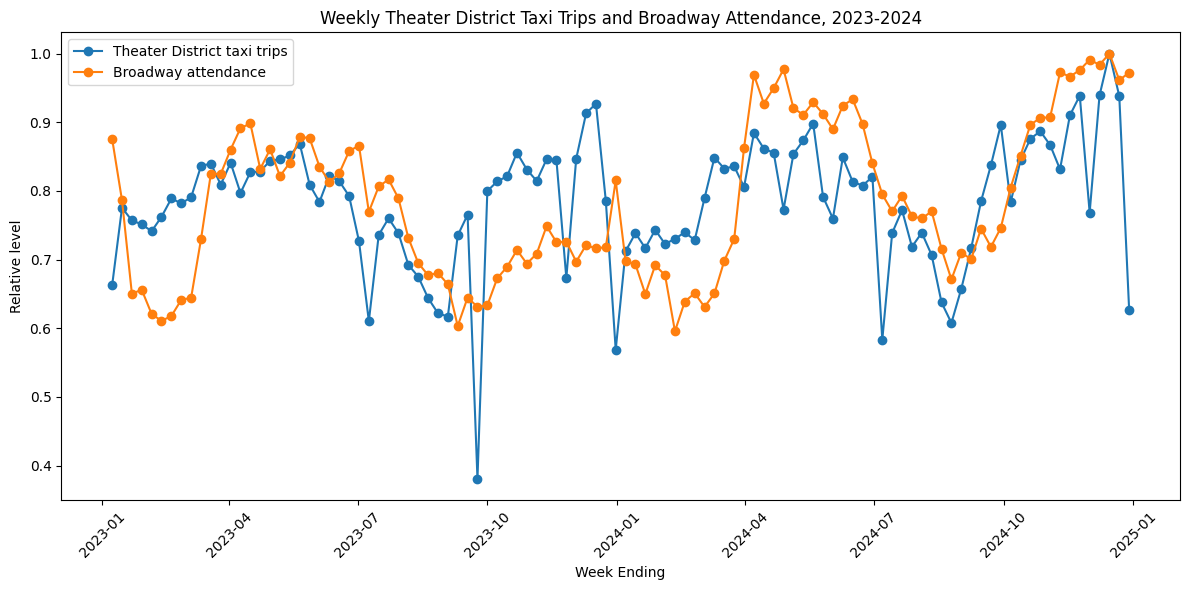

In [37]:
plt.figure(figsize=(12, 6))

plt.plot(
    plot_data["week_ending"],
    plot_data["trips_scaled"],
    marker="o",
    label="Theater District taxi trips"
)

plt.plot(
    plot_data["week_ending"],
    plot_data["attendance_scaled"],
    marker="o",
    label="Broadway attendance"
)

plt.xlabel("Week Ending")
plt.ylabel("Relative level")
plt.title("Weekly Theater District Taxi Trips and Broadway Attendance, 2023-2024")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

Check correlation.

In [38]:
plot_data["weekly_trips"].corr(plot_data["attendance"])

np.float64(0.4357069479949729)

Check if the correlation is actually statistically significant.

In [39]:
from scipy import stats

pearson_r, pearson_p = stats.pearsonr(plot_data["weekly_trips"], plot_data["attendance"])
spearman_r, spearman_p = stats.spearmanr(plot_data["weekly_trips"], plot_data["attendance"])

print("Yellow Taxi (Theater District) vs Broadway attendance")
print(f"  Pearson  r = {pearson_r:.4f}  (p = {pearson_p:.4g})")
print(f"  Spearman r = {spearman_r:.4f}  (p = {spearman_p:.4g})")

Yellow Taxi (Theater District) vs Broadway attendance
  Pearson  r = 0.4357  (p = 3.786e-06)
  Spearman r = 0.4731  (p = 3.956e-07)


Remove the shared trend (both series drifting up toward December) and check if the relationship still holds.

In [40]:
plot_data_sorted = plot_data.sort_values("week_ending").reset_index(drop=True)
trips_pct_change = plot_data_sorted["weekly_trips"].pct_change()
attendance_pct_change = plot_data_sorted["attendance"].pct_change()

detrended_r, detrended_p = stats.pearsonr(
    trips_pct_change.dropna(), attendance_pct_change.dropna()
)
print(f"De-trended (week-over-week change) correlation: "
      f"r = {detrended_r:.4f}  (p = {detrended_p:.4g})")

De-trended (week-over-week change) correlation: r = -0.0249  (p = 0.8029)


Compare against the control zone (Murray Hill).

In [41]:
control_pearson_r, control_pearson_p = stats.pearsonr(
    control_plot_data["weekly_trips"], control_plot_data["attendance"]
)

print(f"Control zone ({control_zone_name}) vs Broadway attendance")
print(f"  Pearson r = {control_pearson_r:.4f}  (p = {control_pearson_p:.4g})")

print("\nComparison:")
print(f"  Theater District r = {pearson_r:.4f}")
print(f"  Control zone r     = {control_pearson_r:.4f}")
print(f"  Difference          = {pearson_r - control_pearson_r:.4f}")

Control zone (Murray Hill) vs Broadway attendance
  Pearson r = 0.3108  (p = 0.001321)

Comparison:
  Theater District r = 0.4357
  Control zone r     = 0.3108
  Difference          = 0.1249


Plot theater vs control vs attendance.

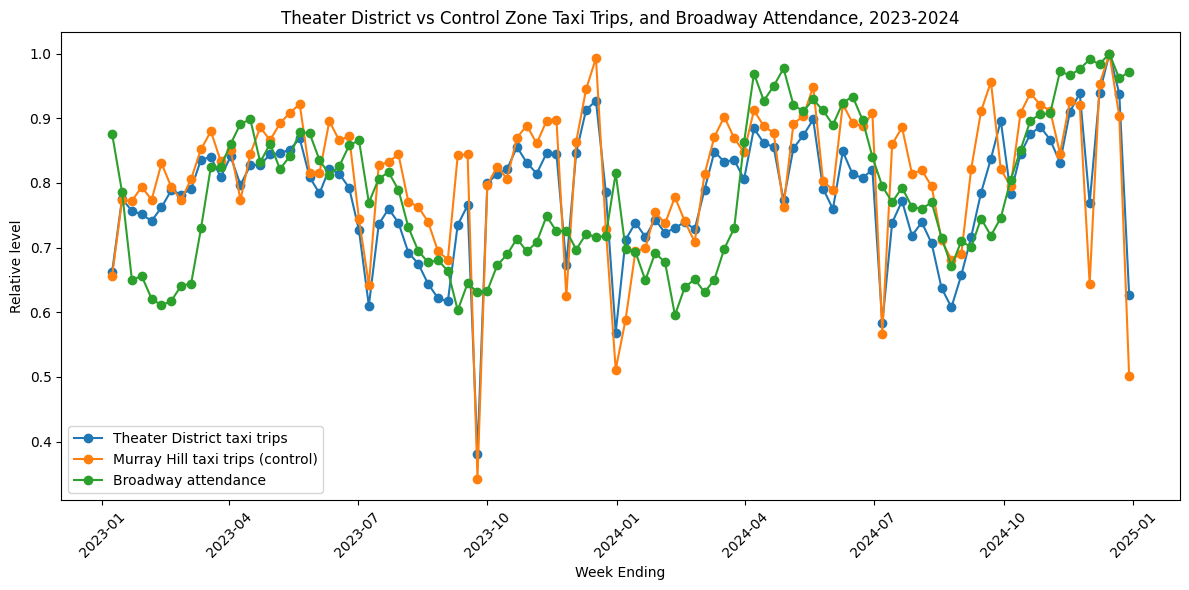

In [42]:
control_plot_data["trips_scaled"] = (
    control_plot_data["weekly_trips"] / control_plot_data["weekly_trips"].max()
)

plt.figure(figsize=(12, 6))
plt.plot(plot_data["week_ending"], plot_data["trips_scaled"],
         marker="o", label="Theater District taxi trips")
plt.plot(control_plot_data["week_ending"], control_plot_data["trips_scaled"],
         marker="o", label=f"{control_zone_name} taxi trips (control)")
plt.plot(plot_data["week_ending"], plot_data["attendance_scaled"],
         marker="o", label="Broadway attendance")
plt.xlabel("Week Ending")
plt.ylabel("Relative level")
plt.title("Theater District vs Control Zone Taxi Trips, and Broadway Attendance, 2023-2024")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

Do the same comparison for HVFHV.

In [43]:
fhvhv_pearson_r, fhvhv_pearson_p = stats.pearsonr(
    fhvhv_plot_data["weekly_trips"], fhvhv_plot_data["attendance"]
)
fhvhv_spearman_r, fhvhv_spearman_p = stats.spearmanr(
    fhvhv_plot_data["weekly_trips"], fhvhv_plot_data["attendance"]
)

print("HVFHV (Theater District) vs Broadway attendance")
print(f"  Pearson  r = {fhvhv_pearson_r:.4f}  (p = {fhvhv_pearson_p:.4g})")
print(f"  Spearman r = {fhvhv_spearman_r:.4f}  (p = {fhvhv_spearman_p:.4g})")

HVFHV (Theater District) vs Broadway attendance
  Pearson  r = 0.0126  (p = 0.8993)
  Spearman r = 0.0017  (p = 0.9862)


Check if the Yellow Taxi and HVFHV correlations are different from each other or just noise.

In [44]:
def fisher_z_test(r1, n1, r2, n2):
    z1 = np.arctanh(r1)
    z2 = np.arctanh(r2)
    se = np.sqrt(1 / (n1 - 3) + 1 / (n2 - 3))
    z_stat = (z1 - z2) / se
    p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))
    return z_stat, p_value

z_stat, z_p = fisher_z_test(pearson_r, len(plot_data), fhvhv_pearson_r, len(fhvhv_plot_data))
print(f"Yellow Taxi r = {pearson_r:.4f} vs HVFHV r = {fhvhv_pearson_r:.4f}")
print(f"Fisher z = {z_stat:.3f}, p = {z_p:.4g}")

if z_p < 0.05:
    print("The two correlations are significantly different.")
else:
    print(f"Cannot reject that they're the same underlying relationship")

Yellow Taxi r = 0.4357 vs HVFHV r = 0.0126
Fisher z = 3.229, p = 0.001243
The two correlations are significantly different.


Do the same for HVFHV in the control zone to do all four combinations (Yellow/HVFHV and Theater/Control).

In [45]:
fhvhv_control_pearson_r, fhvhv_control_pearson_p = stats.pearsonr(
    fhvhv_control_plot_data["weekly_trips"], fhvhv_control_plot_data["attendance"]
)
print(f"HVFHV ({control_zone_name}, control) vs Broadway attendance")
print(f"  Pearson r = {fhvhv_control_pearson_r:.4f}  (p = {fhvhv_control_pearson_p:.4g})")

HVFHV (Murray Hill, control) vs Broadway attendance
  Pearson r = -0.1453  (p = 0.1412)


Check whether HVFHV's weak Theater District result is because HVFHV doesn't track Broadway specifically (its control-zone correlation should be similarly weak), or because it doesn't track the general seasonal trend either.

In [46]:
z_stat_fh, z_p_fh = fisher_z_test(
    fhvhv_pearson_r, len(fhvhv_plot_data), fhvhv_control_pearson_r, len(fhvhv_control_plot_data)
)
print("2x2 summary (Pearson r vs Broadway attendance):")
print(f"                  Theater District   {control_zone_name} (control)")
print(f"  Yellow Taxi     {pearson_r:.4f}             {control_pearson_r:.4f}")
print(f"  HVFHV           {fhvhv_pearson_r:.4f}             {fhvhv_control_pearson_r:.4f}")
print()
print(f"HVFHV Theater vs HVFHV Control: Fisher z = {z_stat_fh:.3f}, p = {z_p_fh:.4g}")
if z_p_fh < 0.05:
    print("-> HVFHV's Theater District correlation is itself different from its own control-zone "
          "correlation, so HVFHV does show some Broadway-specific signal, just weaker than Yellow Taxi's.")
else:
    print("-> No significant difference between HVFHV's two zones: whatever weak relationship HVFHV "
          "has with attendance doesn't appear to be specific to the Theater District at all.")

2x2 summary (Pearson r vs Broadway attendance):
                  Theater District   Murray Hill (control)
  Yellow Taxi     0.4357             0.3108
  HVFHV           0.0126             -0.1453

HVFHV Theater vs HVFHV Control: Fisher z = 1.129, p = 0.259
-> No significant difference between HVFHV's two zones: whatever weak relationship HVFHV has with attendance doesn't appear to be specific to the Theater District at all.


Plot Yellow Taxi vs HVFHV vs attendance.

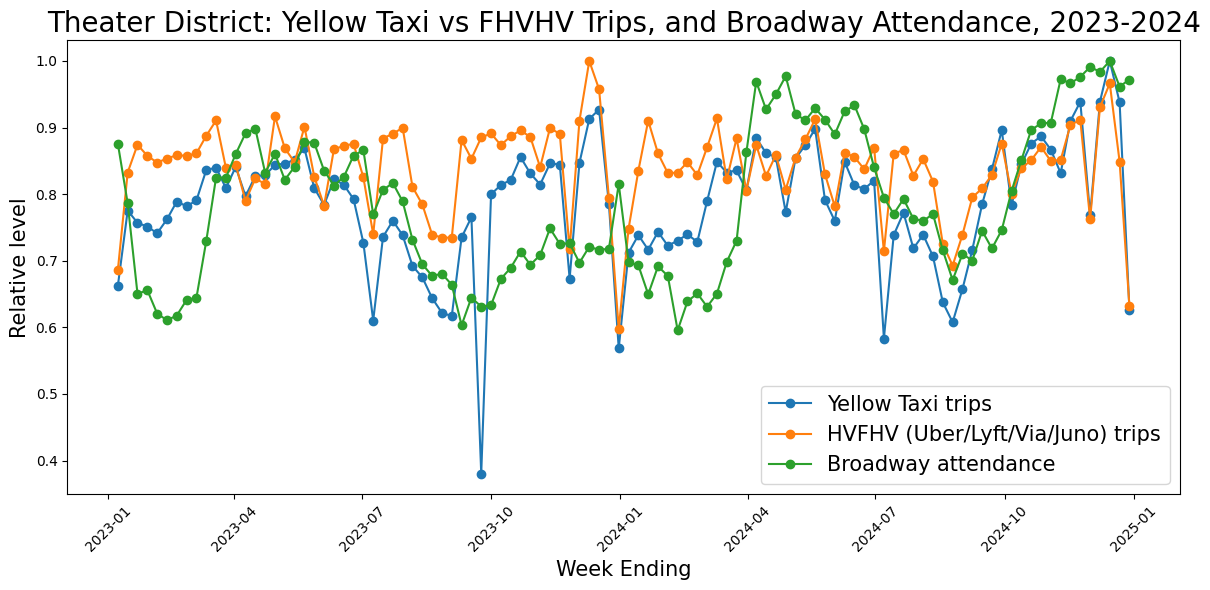

In [47]:
fhvhv_plot_data["trips_scaled"] = (
    fhvhv_plot_data["weekly_trips"] / fhvhv_plot_data["weekly_trips"].max()
)

plt.figure(figsize=(12, 6))
plt.plot(plot_data["week_ending"], plot_data["trips_scaled"],
         marker="o", label="Yellow Taxi trips")
plt.plot(fhvhv_plot_data["week_ending"], fhvhv_plot_data["trips_scaled"],
         marker="o", label="HVFHV (Uber/Lyft/Via/Juno) trips")
plt.plot(plot_data["week_ending"], plot_data["attendance_scaled"],
         marker="o", label="Broadway attendance")
plt.xlabel("Week Ending",fontsize=15)
plt.ylabel("Relative level", fontsize=15)
plt.title("Theater District: Yellow Taxi vs FHVHV Trips, and Broadway Attendance, 2023-2024",fontsize=20)
plt.xticks(rotation=45)
plt.legend(fontsize=15)
plt.tight_layout()
plt.savefig("../plots/trip_pattern.png", dpi=150, bbox_inches="tight")
plt.show()

Look at pickup timing by hour of day and day of week.

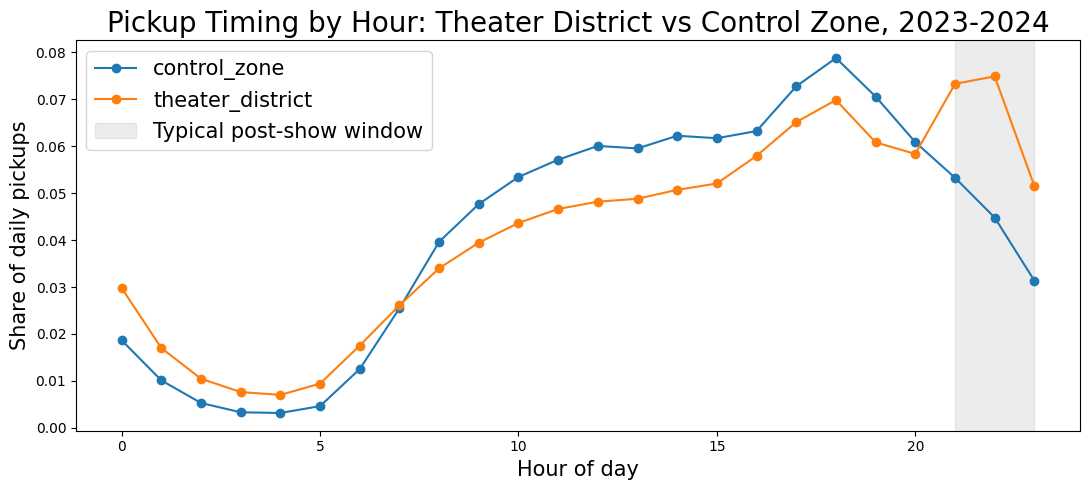

In [48]:
hourly_pattern = pd.read_csv(f"{analysis_ready_dir}/hourly_pattern.csv")
dow_pattern = pd.read_csv(f"{analysis_ready_dir}/dow_pattern.csv")

pivot = hourly_pattern.pivot(index="pickup_hour", columns="zone_type", values="trip_count")
pivot = pivot.div(pivot.sum(axis=0), axis=1)  # normalise so zones are comparable regardless of total volume

fig, ax = plt.subplots(figsize=(11, 5))
pivot.plot(ax=ax, marker="o")
ax.set_xlabel("Hour of day",fontsize=15)
ax.set_ylabel("Share of daily pickups", fontsize=15)
ax.set_title("Pickup Timing by Hour: Theater District vs Control Zone, 2023-2024",fontsize=20)
ax.axvspan(21, 23, color="gray", alpha=0.15, label="Typical post-show window")
ax.legend(fontsize=15)
plt.tight_layout()
plt.savefig("../plots/hourly_pattern.png", dpi=150, bbox_inches="tight")
plt.show()

Plot the day-of-week pattern.

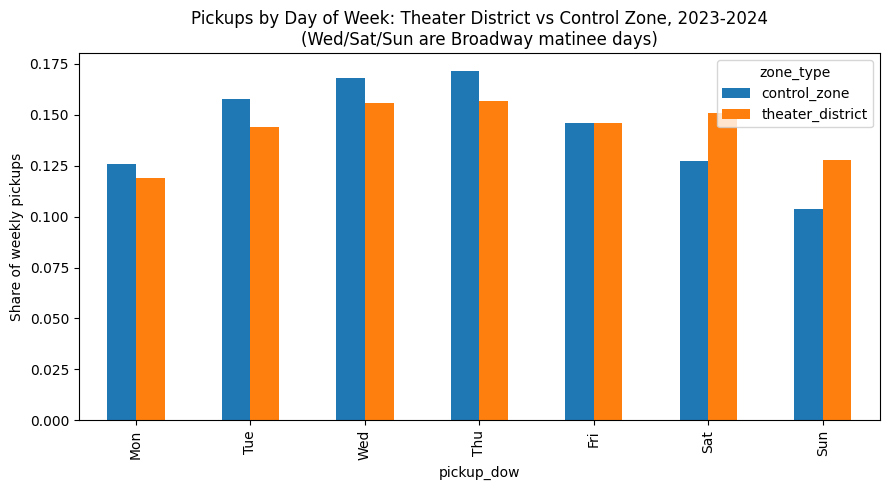

In [49]:
dow_order = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
dow_pivot = dow_pattern.pivot_table(index="pickup_dow", columns="zone_type", values="trip_count", aggfunc="sum")
dow_pivot = dow_pivot.reindex(dow_order)
dow_pivot = dow_pivot.div(dow_pivot.sum(axis=0), axis=1)
fig, ax = plt.subplots(figsize=(9, 5))
dow_pivot.plot(kind="bar", ax=ax)
ax.set_ylabel("Share of weekly pickups")
ax.set_title("Pickups by Day of Week: Theater District vs Control Zone, 2023-2024\n(Wed/Sat/Sun are Broadway matinee days)")
plt.tight_layout()
plt.savefig("../plots/dow_pattern.png", dpi=150, bbox_inches="tight")
plt.show()

Check the distribution of weekly trips and flag any outlier weeks.

count       104.000000
mean      78898.865385
std        9392.230427
min       38333.000000
25%       74311.750000
50%       79778.000000
75%       85082.000000
max      100737.000000
Name: weekly_trips, dtype: float64

Skew: -0.983


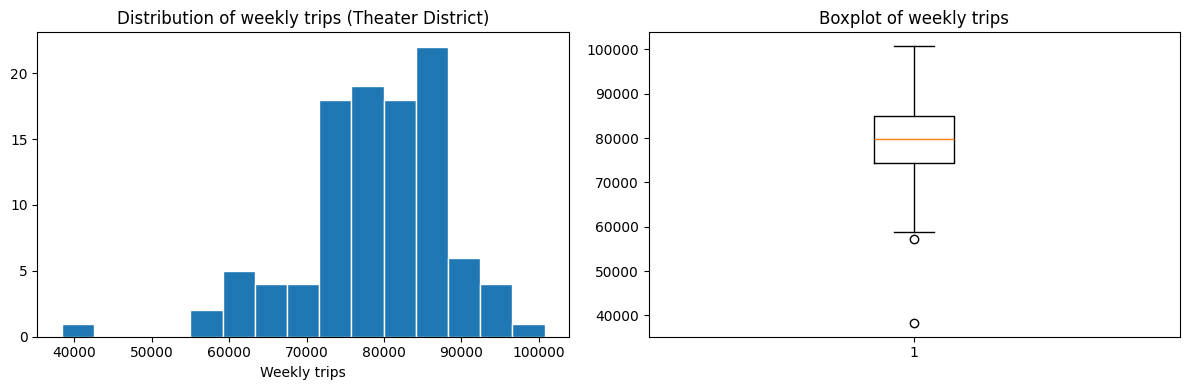

In [50]:
print(plot_data["weekly_trips"].describe())
print()
print(f"Skew: {plot_data['weekly_trips'].skew():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(plot_data["weekly_trips"], bins=15, edgecolor="white")
axes[0].set_title("Distribution of weekly trips (Theater District)")
axes[0].set_xlabel("Weekly trips")

axes[1].boxplot(plot_data["weekly_trips"], vert=True)
axes[1].set_title("Boxplot of weekly trips")
plt.tight_layout()
plt.show()

Flag any outlier weeks using IQR.

In [51]:
# IQR-based outlier flagging
q1, q3 = plot_data["weekly_trips"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

outliers = plot_data[(plot_data["weekly_trips"] < lower) | (plot_data["weekly_trips"] > upper)]
print(f"IQR bounds: [{lower:.0f}, {upper:.0f}]")
print(f"Outlier weeks ({len(outliers)}):")
print(outliers[["week_ending", "weekly_trips", "attendance"]].to_string(index=False))

IQR bounds: [58156, 101237]
Outlier weeks (2):
week_ending  weekly_trips  attendance
 2023-09-24         38333    198785.0
 2023-12-31         57271    256751.0


Check if fares and tips show the same pattern as trip counts.

In [52]:
# Do fares/tips (revenue, not just trip count) show the same relationship with attendance?
fares_r, fares_p = stats.pearsonr(plot_data["weekly_fares"], plot_data["attendance"])
tips_r, tips_p = stats.pearsonr(plot_data["weekly_tips"], plot_data["attendance"])

print(f"Weekly fares vs attendance (pearson): r = {fares_r:.4f}  (p = {fares_p:.4g})")
print(f"Weekly tips  vs attendance (pearson): r = {tips_r:.4f}  (p = {tips_p:.4g})")

fares_r, fares_p = stats.spearmanr(plot_data["weekly_fares"], plot_data["attendance"])
tips_r, tips_p = stats.spearmanr(plot_data["weekly_tips"], plot_data["attendance"])

print(f"Weekly fares vs attendance (spearman): r = {fares_r:.4f}  (p = {fares_p:.4g})")
print(f"Weekly tips  vs attendance (spearman): r = {tips_r:.4f}  (p = {tips_p:.4g})")

Weekly fares vs attendance (pearson): r = 0.4823  (p = 2.164e-07)
Weekly tips  vs attendance (pearson): r = 0.3811  (p = 6.567e-05)
Weekly fares vs attendance (spearman): r = 0.4788  (p = 2.729e-07)
Weekly tips  vs attendance (spearman): r = 0.3902  (p = 4.219e-05)


Correlation heatmap of all the weekly numbers together.

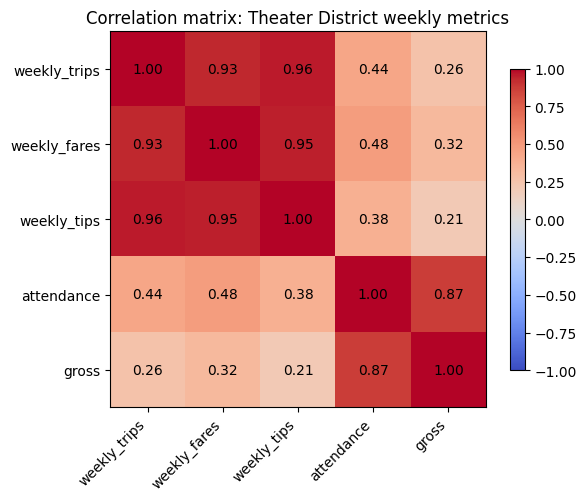

In [53]:
# Correlation heatmap across all numeric columns
import numpy as np

corr_cols = ["weekly_trips", "weekly_fares", "weekly_tips", "attendance", "gross"]
corr_matrix = plot_data[corr_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols))); ax.set_xticklabels(corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols))); ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr_matrix.iloc[i,j]:.2f}", ha="center", va="center")
plt.colorbar(im, shrink=0.8)
plt.title("Correlation matrix: Theater District weekly metrics")
plt.tight_layout()
plt.show()

Scatter plot of trips against attendance, with a regression line.

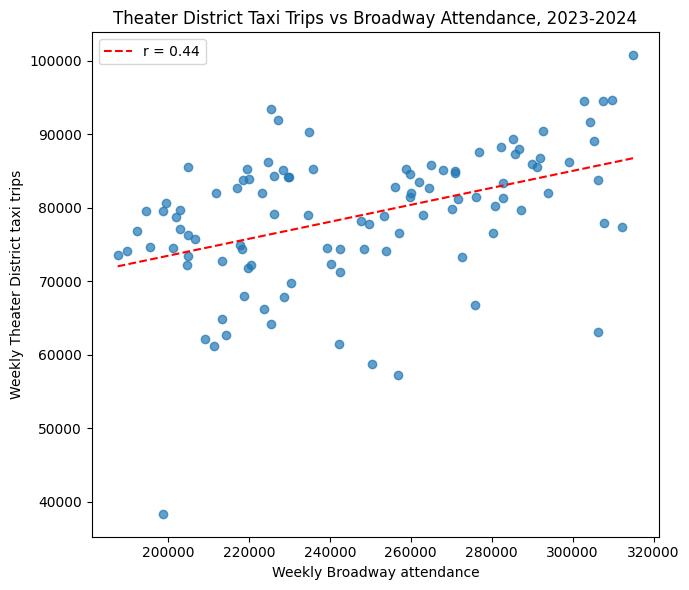

In [54]:
scatter_r, scatter_p = stats.pearsonr(plot_data["attendance"], plot_data["weekly_trips"])

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(plot_data["attendance"], plot_data["weekly_trips"], alpha=0.7)
m, b = np.polyfit(plot_data["attendance"], plot_data["weekly_trips"], 1)
x_line = np.linspace(plot_data["attendance"].min(), plot_data["attendance"].max(), 100)
ax.plot(x_line, m * x_line + b, color="red", linestyle="--", label=f"r = {scatter_r:.2f}")
ax.set_xlabel("Weekly Broadway attendance")
ax.set_ylabel("Weekly Theater District taxi trips")
ax.set_title("Theater District Taxi Trips vs Broadway Attendance, 2023-2024")
ax.legend()
plt.tight_layout()
plt.show()

Check if the four-zone Theater District aggregate is diluted by zones that only contain one or two theaters and are mostly generic activity. Compare the full aggregate against the single most theater-dense zone on its own.

In [55]:
core_pearson_r, core_pearson_p = stats.pearsonr(
    core_plot_data["weekly_trips"], core_plot_data["attendance"]
)
core_spearman_r, core_spearman_p = stats.spearmanr(
    core_plot_data["weekly_trips"], core_plot_data["attendance"]
)

print("Core theater zone (most theater-dense zone only) vs Broadway attendance")
print(f"  Pearson  r = {core_pearson_r:.4f}  (p = {core_pearson_p:.4g})")
print(f"  Spearman r = {core_spearman_r:.4f}  (p = {core_spearman_p:.4g})")
print()
print("Comparison:")
print(f"  Full 4-zone aggregate  r = {pearson_r:.4f}")
print(f"  Core zone only         r = {core_pearson_r:.4f}")
print(f"  Difference              = {core_pearson_r - pearson_r:.4f}")

Core theater zone (most theater-dense zone only) vs Broadway attendance
  Pearson  r = 0.4454  (p = 2.167e-06)
  Spearman r = 0.4914  (p = 1.182e-07)

Comparison:
  Full 4-zone aggregate  r = 0.4357
  Core zone only         r = 0.4454
  Difference              = 0.0096


Test whether that difference is actually statistically significant.

In [56]:
# Formally test whether the core-zone correlation is significantly stronger
# than the full 4-zone aggregate's correlation
z_stat_dilution, z_p_dilution = fisher_z_test(
    core_pearson_r, len(core_plot_data), pearson_r, len(plot_data)
)
print(f"Fisher z (core zone vs full aggregate) = {z_stat_dilution:.3f}, p = {z_p_dilution:.4g}")

if core_pearson_r > pearson_r and z_p_dilution < 0.05:
    print("-> The full 4-zone aggregate IS significantly diluted. The single most "
          "theater-dense zone shows a meaningfully stronger relationship with attendance "
          "on its own -- the other zones are pulling the aggregate toward looking like "
          "general Midtown activity.")
elif core_pearson_r > pearson_r:
    print("-> The core zone shows a numerically stronger correlation, but the difference "
          "is not statistically significant at this sample size -- suggestive of dilution, "
          "not conclusive proof of it.")
else:
    print("-> The core zone does NOT show a stronger correlation than the full aggregate. "
          "This does not support the dilution hypothesis -- the other three zones appear "
          "to be carrying genuine Broadway-related signal too, not just noise.")

Fisher z (core zone vs full aggregate) = 0.085, p = 0.9322
-> The core zone shows a numerically stronger correlation, but the difference is not statistically significant at this sample size -- suggestive of dilution, not conclusive proof of it.


Summary of all correlations with Broadway attendance:

In [57]:
print(f"  Yellow Taxi (Theater District)                : r = {pearson_r:.4f}  (p = {pearson_p:.4g})")
print(f"  Yellow Taxi ({control_zone_name}, control)".ljust(48) + f": r = {control_pearson_r:.4f}  (p = {control_pearson_p:.4g})")
print(f"  Yellow Taxi (de-trended, week-over-week change): r = {detrended_r:.4f}  (p = {detrended_p:.4g})")
print(f"  HVFHV (Theater District)                       : r = {fhvhv_pearson_r:.4f}  (p = {fhvhv_pearson_p:.4g})")
print(f"  HVFHV ({control_zone_name}, control)".ljust(48) + f": r = {fhvhv_control_pearson_r:.4f}  (p = {fhvhv_control_pearson_p:.4g})")

  Yellow Taxi (Theater District)                : r = 0.4357  (p = 3.786e-06)
  Yellow Taxi (Murray Hill, control)            : r = 0.3108  (p = 0.001321)
  Yellow Taxi (de-trended, week-over-week change): r = -0.0249  (p = 0.8029)
  HVFHV (Theater District)                       : r = 0.0126  (p = 0.8993)
  HVFHV (Murray Hill, control)                  : r = -0.1453  (p = 0.1412)
